## {Gaussian, Uniform} to 8-Gaussian, guidance with Learned, MC, CEG

In [1]:
%load_ext autoreload
%autoreload 2

from functools import partial
from typing import List, Tuple
from guided_flow.backbone.mlp import MLP
from guided_flow.backbone.wrapper import ExpEnergyMLPWrapper, GuidedMLPWrapper, MLPWrapper
from guided_flow.config.guidance_training import GuidanceTrainingConfig
from guided_flow.config.sampling import GuideFnConfig
from guided_flow.distributions.base import BaseDistribution, get_distribution
from guided_flow.backbone.mlp import MLP, EnergyMLP
from guided_flow.distributions.gaussian import GaussianDistribution
from guided_flow.flow.optimal_transport import OTPlanSampler
from guided_flow.guidance.gradient_guidance import wrap_grad_fn
from guided_flow.utils.misc import deterministic
from guided_flow.utils.metrics import compute_w2 as w2
import torch
from torchdyn.core import NeuralODE
import numpy as np
from torch.distributions import Normal, Independent
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os
from tqdm import tqdm
from guided_flow.config.sampling import ODEConfig


# from guided_flow.utils.kl_divergence import compute_kl_divergence
MLP_WIDTH = 256
TRAINING_B = 256 # OT CFM training batch size


def sample_x1_frompeJ(x1_sampler, x1_dist, device, B):
    x1 = None
    while x1 is None or x1.shape[0] < B:
        x1_ = x1_sampler(B).to(device)
        weights = torch.exp(-x1_dist.get_J(x1_))
        acc_prob = weights / weights.max()
        random_numbers = torch.rand(B, device=device)
        x1_ = x1_[random_numbers < acc_prob]
        if x1 is None:
            x1 = x1_
        else:
            x1 = torch.cat([x1, x1_], 0)
    x1 = x1[:B]
    return x1


def compute_w2(trajs, cfgs: List[GuideFnConfig]):
    w2s = []
    for traj, cfg in zip(trajs, cfgs):
        x0_dist = get_distribution(cfg.dist_pair[0])
        x1_dist = get_distribution(cfg.dist_pair[1])
        
        x1 = sample_x1_frompeJ(x1_dist.sample, x1_dist, cfg.ode_cfg.device, cfg.ode_cfg.batch_size)
        w2s.append(w2(traj[-1], x1))
    return w2s


def get_mc_guide_fn(x0_dist: BaseDistribution, x1_dist: BaseDistribution, mc_cfg: GuideFnConfig, cfm: str,asym=False):

    def log_cfm_p_t1(x1, xt, t):
        # xt = t x1 + (1 - t) x0 -> x0 = xt / (1 - t) - t / (1 - t) x1
        x0 = xt / (1 - t + mc_cfg.ep) - (t + mc_cfg.ep) / (1 - t + mc_cfg.ep) * x1 # (B, 2)
        p1t = x0_dist.prob(x0).clamp(1e-8) / (1 - t[0] + mc_cfg.ep) ** 2 # (B,)
        log_p1t = p1t.log()
        # print(log_p1t.mean())
        return log_p1t
        
    def guide_fn(t, x, dx_dt, model, x0=None, x1=None, Jx1=None):
        """
        Args:
            t: Tensor, shape (b, 1)
            x: Tensor, shape (b, dim)
            dx_dt: Tensor, shape (b, dim)
            model: MLP
        """
        # estimate E (e^{-J} / Z - 1) * u
        b = x.shape[0]
        B = mc_cfg.mc_batch_size
        x_ = x.repeat(B, 1) # (MC_B * b, 2)
        t_ = t.repeat(B * b, 1) # (MC_B * b)
        if cfm == 'cfm':
            log_p_t1_x = log_cfm_p_t1(x1, x_, t_) # (MC_B * b) # TODO
            log_p_t_x = log_p_t1_x.reshape(B, b, 1).logsumexp(0) - torch.log(torch.tensor(B, device=x.device)) # (MC_B, B, 1) -> (B, 1)
            log_p_t1_x_times_J_ = (log_p_t1_x + torch.log(Jx1)).reshape(B, b, 1) # (MC_B * b) -> (MC_B, b, 1)            
            logZ = torch.logsumexp(log_p_t1_x_times_J_, 0) - torch.log(torch.tensor(B, device=x.device)) - log_p_t_x # (b, 1)

            Z = torch.exp(logZ)
            u = (x1 - x_) / (1 - t_ + mc_cfg.ep) # (MC_B * b, dim)

            g = (log_p_t1_x.reshape(B, b, 1) - log_p_t_x.unsqueeze(0)).exp() * (Jx1.reshape(B, b, 1) / (Z + 1e-8).unsqueeze(0) - 1) * u.reshape(B, b, 2) # (MC_B, b, dim)

            return g.mean(0)

    
    x1 = x1_dist.sample(mc_cfg.mc_batch_size).to(mc_cfg.ode_cfg.device).unsqueeze(0).repeat(mc_cfg.ode_cfg.batch_size, 1, 1).permute(1, 0, 2).reshape(-1, 2)
    if not asym:
        Jx1 = torch.exp(-mc_cfg.scale * x1_dist.get_J(x1)) 
    else: 
        Jx1 = torch.exp(-mc_cfg.scale * x1_dist.get_J_asym(x1)) 
    return partial(
        guide_fn, 
        x1=x1, 
        Jx1=Jx1
    )


def get_guide_fn(dist: BaseDistribution, cfg: GuideFnConfig):
    def guide_fn(t, x, dx_dt, model):

        if cfg.guide_type == 'g_cov_A' or 'g_cov_A_lya':
            x1_pred = x + dx_dt * (1 - t)
            J = dist.get_J(x1_pred)
            try:
                with torch.enable_grad():
                    x1_pred = x1_pred.requires_grad_(True)
                    J = dist.get_J(x1_pred)
                    grad = -torch.autograd.grad(J.sum(), x1_pred, create_graph=True)[0]
                    return grad
            except Exception as e:
                return torch.zeros_like(x)
        
        
        elif cfg.guide_type == 'g_cov_G' or 'g_cov_G_lya':
            with torch.enable_grad():
                x = x.requires_grad_(True)
                x1_pred = x + model(torch.cat([x, t.repeat(x.shape[0])[:, None]], 1)) * (1 - t)
                J = dist.get_J(x1_pred)
                try:
                    grad = -torch.autograd.grad(J.sum(), x, create_graph=True)[0]
                    return grad
                except Exception as e:
                    return torch.zeros_like(x)
        elif cfg.guide_type == 'grad' or 'grad_lya':
            with torch.enable_grad():
                x = x.requires_grad_(True)
                J = dist.get_J(x)
                try:
                    grad = -torch.autograd.grad(J.sum(), x, create_graph=True)[0]
                    return grad
                except Exception as e:
                    return torch.zeros_like(x)
        else:
            raise ValueError(f"Unknown guide function: {cfg.guide_type}")
    # make scale and schedule
    return wrap_grad_fn(cfg.guide_scale, cfg.guide_schedule, guide_fn)

def get_sim_mc_guide_fn(x1_dist: BaseDistribution, cfg: GuideFnConfig):
    def guide_fn(t, x, dx_dt, model):
        """
        Implements guidance following Eq. 12
        Args:
            t: flow time. float
            x: current sample x_t. Tensor, shape (b, dim)
            dx_dt: current predicted VF. Tensor, shape (b, dim)
            model: flow model. MLP
        """
        x1_pred = x + dx_dt * (1 - t) # (B, 2)
        std = cfg.sim_mc_std
        
        x1 = torch.randn_like(x1_pred.unsqueeze(0).repeat(cfg.sim_mc_n, 1, 1)) * std + x1_pred # (cfg.sim_mc_n, B, 2)
        Jx1_ = torch.exp(-cfg.scale * x1_dist.get_J(x1.reshape(-1, 2))).reshape(cfg.sim_mc_n, -1) # (cfg.sim_mc_n, B)
        v = (x1 - x) / (1 - t + cfg.ep)  # Conditional VF v_{t|z} in Eq. 12 (cfg.sim_mc_n, B, 2)
        Z = Jx1_.mean(0) + 1e-8  # Z in Eq. 12 (B,)
        g = (Jx1_ / Z - 1).unsqueeze(2) * v  # g in Eq. 12 (cfg.sim_mc_n, B, 2)
        return g.mean(0)
    return wrap_grad_fn(cfg.guide_scale, cfg.guide_schedule, guide_fn)

def evaluate(x0_sampler, x1_sampler, model, guide_fn, cfg: ODEConfig,lya=False,V=None,Vx=None,delta=0.1):
    node = NeuralODE(
        GuidedMLPWrapper(
            model, 
            guide_fn=guide_fn,
            scheduler=lambda t: 1,
            lya = lya,
            V = V,
            Vx = Vx,
            delta = delta
            ), 
            solver="euler", sensitivity="adjoint", atol=1e-4, rtol=1e-4
        )    
    with torch.no_grad():
        traj = node.trajectory(
            x0_sampler(cfg.batch_size).to(cfg.device), 
            t_span=torch.linspace(0, cfg.t_end, cfg.num_steps)
        )
    return traj

def sample_and_compute_w2(guide_cfgs: List[GuideFnConfig]):
    print("Monte Carlo batch size:", guide_cfgs[0].mc_batch_size)

    trajs = []
    delta = 0.25 # intensity of lya
    for cfg in guide_cfgs:

        # Initialize samplers, model and guidance model
        x0_dist = get_distribution(cfg.dist_pair[0])
        x1_dist = get_distribution(cfg.dist_pair[1])

        x0_sampler = x0_dist.sample
        x1_sampler = x1_dist.sample
        cfg.ode_cfg.device = 'cuda:0'
        model = MLP(dim=2, w=MLP_WIDTH, time_varying=True).to(cfg.ode_cfg.device)
        model.load_state_dict(torch.load(f'../logs_v2/{cfg.dist_pair[0]}-{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth'))

        if cfg.guide_type == 'mc':
            # sample using flow model
            traj = evaluate(x0_sampler, x1_sampler, model, get_mc_guide_fn(x0_dist, x1_dist, cfg, cfg.cfm), cfg.ode_cfg)
        elif cfg.guide_type == 'mc_lya':
            # sample using flow model
            traj = evaluate(x0_sampler, x1_sampler, model, get_mc_guide_fn(x0_dist, x1_dist, cfg, cfg.cfm), cfg.ode_cfg,lya=True,V=x1_dist.get_J_asym,Vx=x1_dist.get_J_asym_x,delta=cfg.delta)   
        if cfg.guide_type == 'con':
            # sample using flow model
            traj = evaluate(x0_sampler, x1_sampler, model, get_mc_guide_fn(x0_dist, x1_dist, cfg, cfg.cfm,True), cfg.ode_cfg)
        elif cfg.guide_type == 'con_lya':
            # sample using flow model
            traj = evaluate(x0_sampler, x1_sampler, model, get_mc_guide_fn(x0_dist, x1_dist, cfg, cfg.cfm,True), cfg.ode_cfg,lya=True,V=x1_dist.get_J_asym,Vx=x1_dist.get_J_asym_x,delta=cfg.delta)   
        elif cfg.guide_type == 'learned':
            model_G = MLP(dim=2, out_dim=2, w=MLP_WIDTH, time_varying=True).to(cfg.ode_cfg.device)
            model_G.load_state_dict(torch.load(f'../logs_v2/{cfg.dist_pair[0]}-{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}/guidance_matching_{cfg.gm_type}_scale_{cfg.scale}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth'))
            traj = evaluate(x0_sampler, x1_sampler, model, MLPWrapper(model_G, scheduler=lambda t: 1., clamp=0), cfg.ode_cfg)
        elif cfg.guide_type == 'learned_lya':
            model_G = MLP(dim=2, out_dim=2, w=MLP_WIDTH, time_varying=True).to(cfg.ode_cfg.device)
            model_G.load_state_dict(torch.load(f'../logs_v2/{cfg.dist_pair[0]}-{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}/guidance_matching_{cfg.gm_type}_scale_{cfg.scale}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth'))
            traj = evaluate(x0_sampler, x1_sampler, model, MLPWrapper(model_G, scheduler=lambda t: 1., clamp=0), cfg.ode_cfg,lya=True,V=x1_dist.get_J_asym,Vx=x1_dist.get_J_asym_x,delta=cfg.delta)
        elif cfg.guide_type == 'ceg':
            model_Z = MLP(dim=2, out_dim=1, w=MLP_WIDTH, time_varying=True, exp_final=False).to(cfg.ode_cfg.device)
            model_Z.load_state_dict(torch.load(f'../logs_v2/{cfg.dist_pair[0]}-{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}/ceg_scale_{cfg.scale}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth'))
            traj = evaluate(x0_sampler, x1_sampler, model, ExpEnergyMLPWrapper(model_Z, scheduler=lambda t: 1, clamp=1), cfg.ode_cfg)
        elif cfg.guide_type == 'ceg_lya':
            model_Z = MLP(dim=2, out_dim=1, w=MLP_WIDTH, time_varying=True, exp_final=False).to(cfg.ode_cfg.device)
            model_Z.load_state_dict(torch.load(f'../logs_v2/{cfg.dist_pair[0]}-{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}/ceg_scale_{cfg.scale}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth'))
            traj = evaluate(x0_sampler, x1_sampler, model, ExpEnergyMLPWrapper(model_Z, scheduler=lambda t: 1, clamp=1), cfg.ode_cfg,lya=True,V=x1_dist.get_J_asym,Vx=x1_dist.get_J_asym_x,delta=cfg.delta)
        
        elif cfg.guide_type in ['g_cov_A', 'g_cov_G','grad']:
            traj = evaluate(x0_sampler, x1_sampler, model, get_guide_fn(x1_dist, cfg), cfg.ode_cfg)
        elif cfg.guide_type in ['g_cov_A_lya', 'g_cov_G_lya','grad_lya']:
            traj = evaluate(x0_sampler, x1_sampler, model, get_guide_fn(x1_dist, cfg), cfg.ode_cfg,lya=True,V=x1_dist.get_J_asym,Vx=x1_dist.get_J_asym_x,delta=cfg.delta)
        elif cfg.guide_type == 'g_sim_MC':
            traj = evaluate(x0_sampler, x1_sampler, model, get_sim_mc_guide_fn(x1_dist, cfg), cfg.ode_cfg)
        elif cfg.guide_type == 'g_sim_MC_lya':
            traj = evaluate(x0_sampler, x1_sampler, model, get_sim_mc_guide_fn(x1_dist, cfg), cfg.ode_cfg,lya=True,V=x1_dist.get_J_asym,Vx=x1_dist.get_J_asym_x,delta=cfg.delta)
        trajs.append(traj)
    return trajs, None

deterministic(0)



/tmp/ipykernel_1916/2647414137.py:116: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  blue = cm.get_cmap('coolwarm', 2)(0)
/tmp/ipykernel_1916/2647414137.py:117: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  red = cm.get_cmap('coolwarm', 2)(1)
/home/zjddsg/miniconda3/envs/guided_flow2/lib/python3.10/site-packages/torchdyn/numerics/odeint.py:83: UserWarning: Setting tolerances has no effect on fixed-step methods
  warn("Setting tolerances has no effect on fixed-step methods")


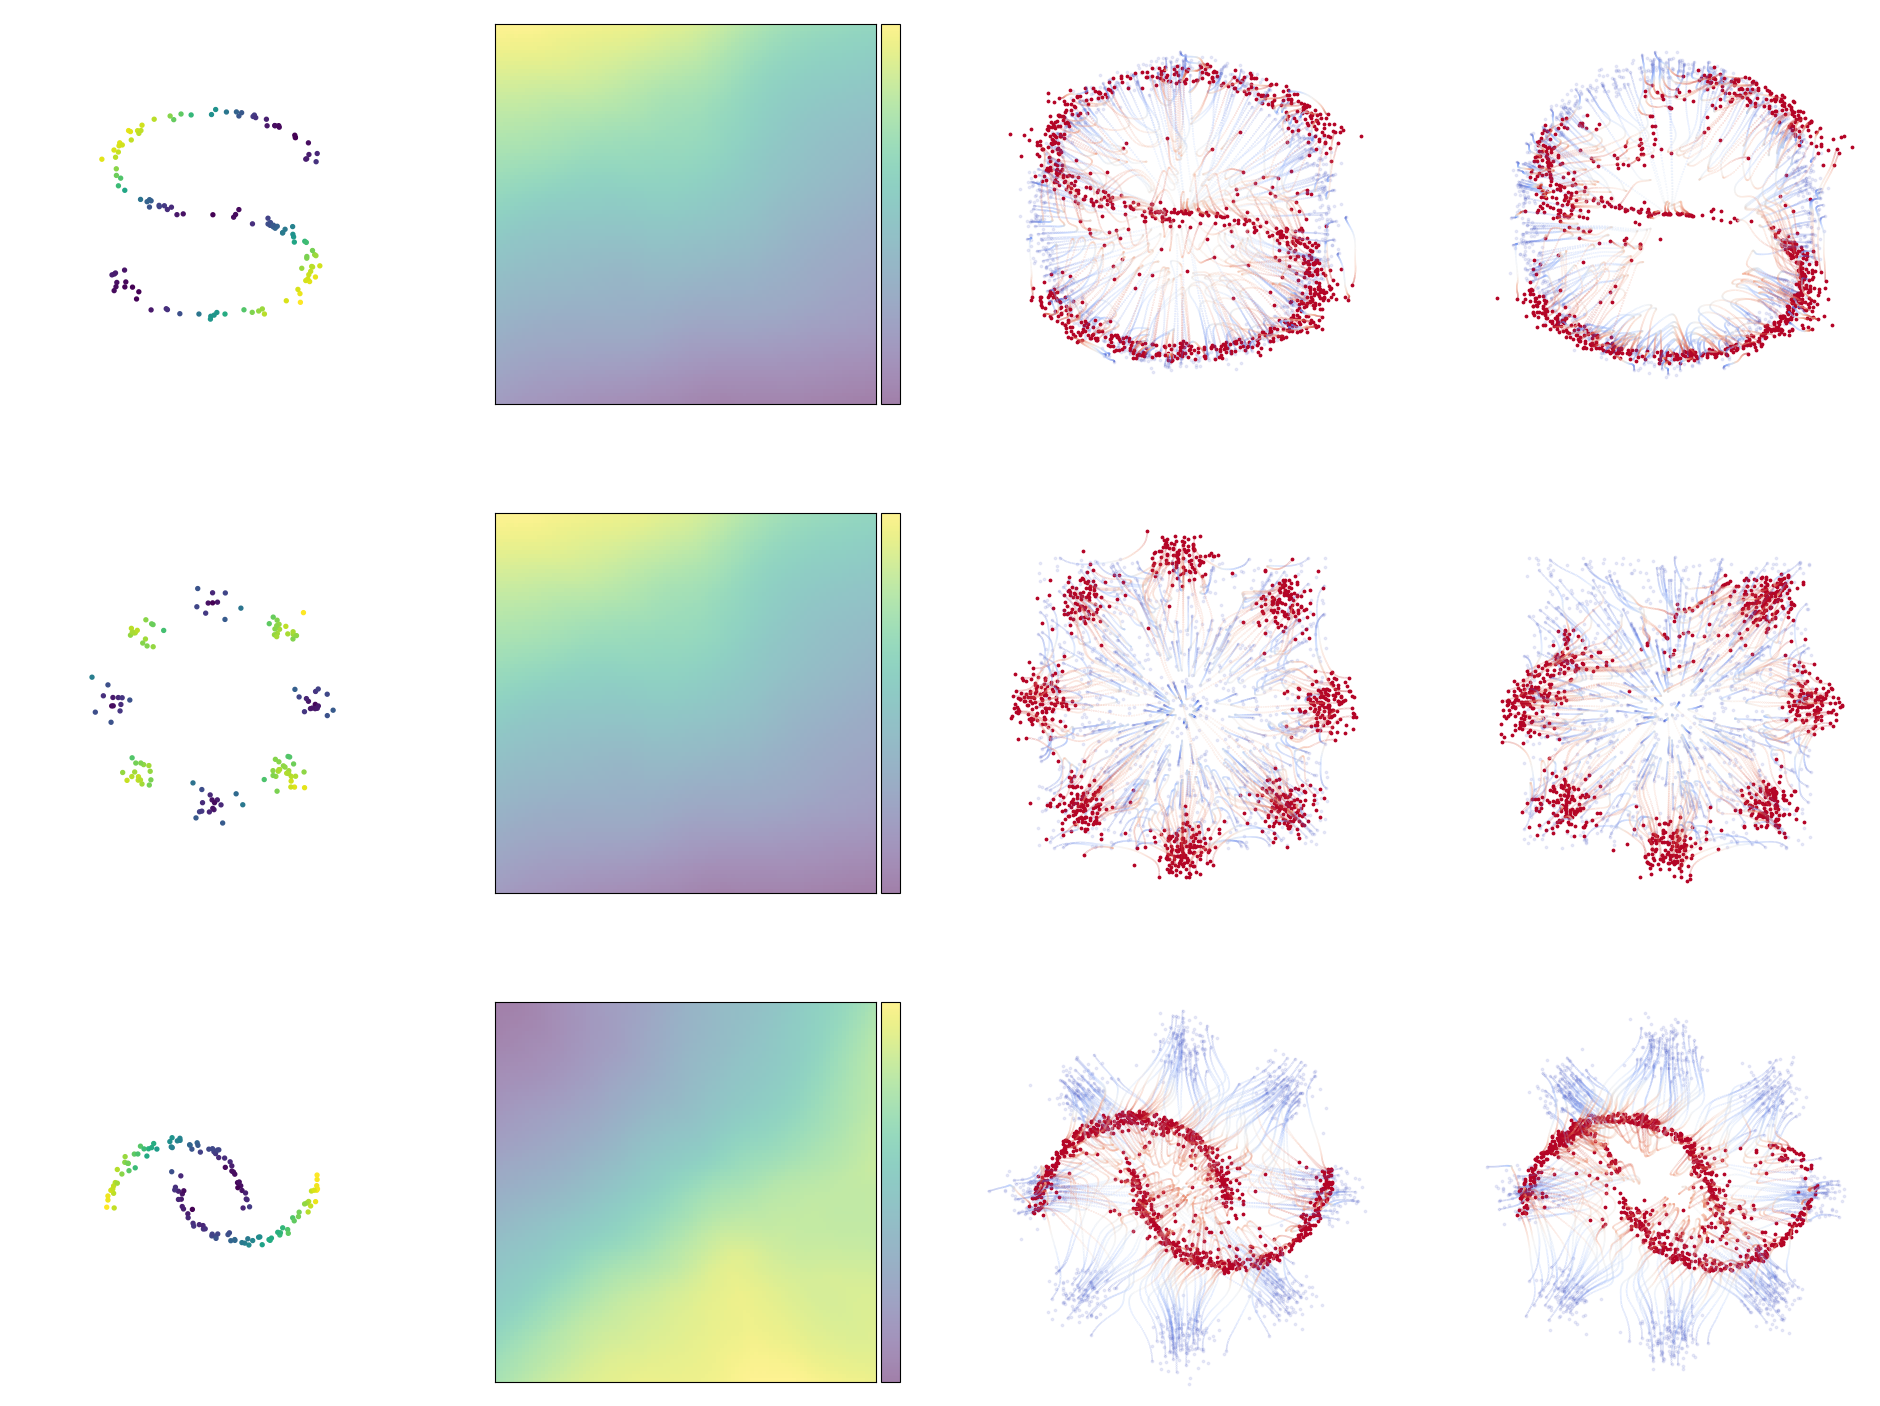

In [ ]:
import matplotlib.pyplot as plt
from guided_flow.distributions.base import get_distribution
from mpl_toolkits.axes_grid1 import make_axes_locatable

def visualize_support_simple(cfgs, n_bg=10240, disp_b=256,cmap='viridis'):
    # 目标分布

    # fig, ax = plt.subplots(figsize=(6,6))

    ndata = 3
    ncols = 4
    size_ratio = 0.7
    ticksize = 10
    fig, axs = plt.subplots(ndata, ncols) 
    r = 6
    fig.set_size_inches(ncols * r, ndata * r)

    for i in range(ndata):
        ax = axs[i,1]
        cfg = cfgs[i]
        log_subfolder = os.path.join(
        "../logs",
        f"{cfg.dist_pair[0]}-{cfg.dist_pair[1]}",
        f"{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}",
        f'n_support={cfg.n_support}'
    )

        fname = f"V_theta_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}_support_dataset.pt"
        fpath = os.path.join(log_subfolder, fname)
        V_net = EnergyMLP(dim=2, out_dim=1, w=128, time_varying=False).to(cfg.ode_cfg.device)
        V_net.load_state_dict(torch.load(os.path.join(log_subfolder, f'V_theta_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth')))
        V_net.eval()
        def V_net_x(x):
            # V = V_net(x) #(B,)
            # @torch.enable_grad()
            # try:
            #     with torch.enable_grad():
            #         x_ = x.requires_grad_(True)
            #         J = V_net(x_)
            #         return torch.autograd.grad(J.sum(), x_, create_graph=True)[0]
            # except Exception as e:
            #     raise ValueError(f"Failed to compute gradient get_J_x for {cfg.J_method}: {e}")
            with torch.enable_grad():
                x_ = x.requires_grad_(True)
                J = V_net(x_)
                return torch.autograd.grad(J.sum(), x_, create_graph=False)[0]
            
        data = torch.load(fpath, map_location="cpu")  # 更稳妥
        Xs, ys = data["Xs"], data["ys"]

        x0_dist = get_distribution(cfg.dist_pair[0])
        x1_dist = get_distribution(cfg.dist_pair[1])
        x0_sampler = x0_dist.sample
        x1_sampler = x1_dist.sample
        x1 = x1_sampler(1024).to(cfg.ode_cfg.device)

        # ax = axs[0, 0]
        grid_size = 100
        xlim, ylim = cfg.xlim * size_ratio, cfg.ylim * size_ratio
        x_s = torch.linspace(-xlim, xlim, grid_size)
        y_s = torch.linspace(-ylim, ylim, grid_size)
        XX, YY = torch.meshgrid(x_s, y_s, indexing='ij')
        grid_points = torch.stack([XX.flatten(), YY.flatten()], dim=1).to(cfg.ode_cfg.device)  # (N, 2)

        # 计算能量 J
        with torch.no_grad():
            J_grid = V_net(grid_points).reshape(grid_size, grid_size).cpu().numpy()

        # 背景热图
        im = ax.imshow(
            J_grid.T,
            extent=[-xlim, xlim, -ylim, ylim],
            origin='lower',
            cmap='viridis',
            alpha=0.5,
            aspect='equal'   # 保持正方形
        )

        # 样本点
        # ax.scatter(x1[:, 0].cpu(), x1[:, 1].cpu(), s=3, color='red')
        ax.set_xlim(-cfg.xlim * size_ratio, cfg.xlim * size_ratio)
        ax.set_ylim(-cfg.ylim * size_ratio, cfg.ylim * size_ratio)
        ax.set_xticks([])
        ax.set_yticks([])
        # ax.axis('off')

        # 用 divider 给 ax 添加 colorbar，保持高度对齐
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.05)  # size 控制宽度, pad 控制间距
        cbar = fig.colorbar(im, cax=cax)
        # cbar.set_label('Energy $J(x,y)$')
        # vmin, vmax = (J_grid.min(), J_grid.max()) 
        cbar.set_ticks([])

        x1_bg = x1_dist.sample(batch_size=n_bg).to(cfg.ode_cfg.device)  # 背景点

        # 转 numpy
        X_bg = x1_bg.cpu().numpy()
        Xs_np = Xs.cpu().numpy()
        ys_np = ys.view(-1).cpu().numpy()

        # 画图

        ax = axs[i,0]
        # ax.scatter(X_bg[:,0], X_bg[:,1], s=2, color='lightgray', alpha=0.5, label='target samples')
        sc = ax.scatter(Xs_np[:,0], Xs_np[:,1], s=8, c=ys_np, cmap=cmap, label='support (Xs)')
        # plt.colorbar(sc, ax=ax, label='Energy ys')
        ax.set_xlim(-cfg.xlim, cfg.xlim)
        ax.set_ylim(-cfg.ylim, cfg.ylim)
        ax.axis('off')
        ax.set_aspect('equal')
        # ax.legend()


        ax = axs[i,2]
        blue = cm.get_cmap('coolwarm', 2)(0)
        red = cm.get_cmap('coolwarm', 2)(1)
        model = MLP(dim=2, w=MLP_WIDTH, time_varying=True).to(cfg.ode_cfg.device)
        model.load_state_dict(torch.load(f'../logs/{cfg.dist_pair[0]}-{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth'))
        model_G =  MLP(dim=2, out_dim=2, w=MLP_WIDTH, time_varying=True).to(cfg.ode_cfg.device)
        model_G.load_state_dict(torch.load(os.path.join(log_subfolder, f'G_phi_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth')))
        traj = evaluate(x0_sampler, x1_sampler, model, MLPWrapper(model_G, scheduler=lambda t: 1., clamp=0), cfg.ode_cfg)
                # traj = evaluate(x0_sampler, x1_sampler, model, MLPWrapper(model_G, scheduler=lambda t: 1., clamp=0), cfg.ode_cfg,lya=True,V=V_net,Vx=V_net_x,delta=cfg.delta)
        idx = torch.randperm(cfg.ode_cfg.batch_size)[:disp_b]
        ax.scatter(traj[0, :, 0].cpu(), traj[0, :, 1].cpu(), s=3, color=blue,alpha=0.1)
        ax.scatter(traj[-1, :, 0].cpu(), traj[-1, :, 1].cpu(), s=3, color=red)
        # plot the trajectory with a gradient color
        colors = torch.linspace(0, 1, cfg.ode_cfg.num_steps).unsqueeze(1).repeat(1, disp_b).flatten().numpy()
        ax.scatter(
            traj[:, idx, 0].flatten().cpu(), 
            traj[:, idx, 1].flatten().cpu(), 
            c=plt.cm.coolwarm(colors), 
            alpha=0.5, s=0.1, marker='.'
        )
        # ax.set_title(f'{cfg.dist_pair[0]} to {cfg.dist_pair[1]}')
        ax.set_xlim(-cfg.xlim * size_ratio, cfg.xlim * size_ratio)
        ax.set_ylim(-cfg.ylim * size_ratio, cfg.ylim * size_ratio)
        ax.axis('off')

        ax.set_aspect('auto')
        
        
        ax = axs[i,3]
        # traj = evaluate(x0_sampler, x1_sampler, model, MLPWrapper(model_G, scheduler=lambda t: 1., clamp=0), cfg.ode_cfg)
        traj = evaluate(x0_sampler, x1_sampler, model, MLPWrapper(model_G, scheduler=lambda t: 1., clamp=0), cfg.ode_cfg,lya=True,V=V_net,Vx=V_net_x,delta=cfg.delta)
        idx = torch.randperm(cfg.ode_cfg.batch_size)[:disp_b]
        ax.scatter(traj[0, :, 0].cpu(), traj[0, :, 1].cpu(), s=3, color=blue,alpha=0.1)
        ax.scatter(traj[-1, :, 0].cpu(), traj[-1, :, 1].cpu(), s=3, color=red)
        # plot the trajectory with a gradient color
        colors = torch.linspace(0, 1, cfg.ode_cfg.num_steps).unsqueeze(1).repeat(1, disp_b).flatten().numpy()
        ax.scatter(
            traj[:, idx, 0].flatten().cpu(), 
            traj[:, idx, 1].flatten().cpu(), 
            c=plt.cm.coolwarm(colors), 
            alpha=0.5, s=0.1, marker='.'
        )
        # ax.set_title(f'{cfg.dist_pair[0]} to {cfg.dist_pair[1]}')
        ax.set_xlim(-cfg.xlim * size_ratio, cfg.xlim * size_ratio)
        ax.set_ylim(-cfg.ylim * size_ratio, cfg.ylim * size_ratio)
        ax.axis('off')

        ax.set_aspect('auto')
    plt.savefig('../figs/lya_s2_synthtic.pdf')
    plt.show()


n = 1024
cfgs = [
    GuideFnConfig(dist_pair=('circle', 's_curve'), n_support=n,mc_batch_size=10240, ep=5e-2, scale=1, ode_cfg=ODEConfig(t_end=0.95, num_steps=100),delta=0.4), 
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), n_support=n,mc_batch_size=10240, ep=1e-3, ode_cfg=ODEConfig(t_end=1, num_steps=100),delta=0.9), 
    GuideFnConfig(dist_pair=('8gaussian', 'moon'), n_support=n,mc_batch_size=1024, ep=1e-2, scale=1, ode_cfg=ODEConfig(t_end=1.0, num_steps=100),delta=0.3), 
]

# cfgs = [
#     GuideFnConfig(dist_pair=('uniform', '8gaussian'), mc_batch_size=10240, ep=1e-3, ode_cfg=ODEConfig(t_end=1, num_steps=100)),
# ]
# log_subfolder = os.path.join(
#     "../logs",
#     f"{cfg.dist_pair[0]}-{cfg.dist_pair[1]}",
#     f"{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}"
# )

# fname = f"V_theta_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}_support_dataset.pt"
# fpath = os.path.join(log_subfolder, fname)

# V_net = EnergyMLP(dim=2, out_dim=1, w=128, time_varying=False).to(cfg.ode_cfg.device)
# V_net.load_state_dict(torch.load(os.path.join(log_subfolder, f'V_theta_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}.pth')))
# print("Loading:", fpath)


visualize_support_simple(cfgs, n_bg=10240,disp_b=256, cmap="viridis")


__data in 8gaussian, scenario 1__

In [8]:
# mc
guide_cfgs_mc_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), mc_batch_size=10240, ep=1e-3, ode_cfg=ODEConfig(t_end=1, num_steps=100)), 
]
cfg_ = guide_cfgs_mc_cfm[0]
print(cfg_.delta)
deterministic(0)
trajs_mc_cfm, w2s_mc_cfm = sample_and_compute_w2(guide_cfgs_mc_cfm)
guide_cfgs_mc_lya_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'),guide_type='mc_lya', mc_batch_size=10240, ep=1e-3, ode_cfg=ODEConfig(t_end=1, num_steps=100)), 
]
deterministic(0)
trajs_mc_lya_cfm, w2s_mc_lya_cfm = sample_and_compute_w2(guide_cfgs_mc_lya_cfm)
# con
guide_cfgs_con_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'),guide_type='con',  mc_batch_size=10240, ep=1e-3, ode_cfg=ODEConfig(t_end=1, num_steps=100)), 
]
deterministic(0)
trajs_con_cfm, w2s_con_cfm = sample_and_compute_w2(guide_cfgs_con_cfm)
guide_cfgs_con_lya_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'),guide_type='con_lya', mc_batch_size=10240, ep=1e-3, ode_cfg=ODEConfig(t_end=1, num_steps=100)), 
]
deterministic(0)
trajs_con_lya_cfm, w2s_con_lya_cfm = sample_and_compute_w2(guide_cfgs_con_lya_cfm)

# gm
guide_cfgs_gm_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='learned', ep=1e-3, gm_type='g3', ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_gm_cfm, w2s_gm_cfm = sample_and_compute_w2(guide_cfgs_gm_cfm)
guide_cfgs_gm_lya_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='learned_lya', ep=1e-3, gm_type='g3', ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_gm_lya_cfm, w2s_gm_lya_cfm = sample_and_compute_w2(guide_cfgs_gm_lya_cfm)

# g_cov_a
guide_cfgs_g_cov_a_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_cov_A', guide_scale=1.0, guide_schedule='linear_decay', ep=1e-3, ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_g_cov_a_cfm, w2s_g_cov_a_cfm = sample_and_compute_w2(guide_cfgs_g_cov_a_cfm)
guide_cfgs_g_cov_a_lya_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_cov_A_lya', guide_scale=1.0, guide_schedule='linear_decay', ep=1e-3, ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_g_cov_a_lya_cfm, w2s_g_cov_a_lya_cfm = sample_and_compute_w2(guide_cfgs_g_cov_a_lya_cfm)
# g_cov_g
guide_cfgs_g_cov_g_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_cov_G', guide_scale=1.0, guide_schedule='linear_decay', ep=1e-3, ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_g_cov_g_cfm, w2s_g_cov_g_cfm = sample_and_compute_w2(guide_cfgs_g_cov_g_cfm)
guide_cfgs_g_cov_g_lya_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_cov_G_lya', guide_scale=1.0, guide_schedule='linear_decay', ep=1e-3, ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_g_cov_g_lya_cfm, w2s_g_cov_g_lya_cfm = sample_and_compute_w2(guide_cfgs_g_cov_g_lya_cfm)
# grad
guide_cfgs_grad_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='grad', guide_scale=1.0, guide_schedule='linear_decay', ep=1e-3, ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_grad_cfm, w2s_grad_cfm = sample_and_compute_w2(guide_cfgs_grad_cfm)
guide_cfgs_grad_lya_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='grad_lya', guide_scale=1.0, guide_schedule='linear_decay', ep=1e-3, ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_grad_lya_cfm, w2s_grad_lya_cfm = sample_and_compute_w2(guide_cfgs_grad_lya_cfm)
# ceg
guide_cfgs_ceg_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='ceg', ep=1e-3, ode_cfg=ODEConfig(t_end=0.95, num_steps=100)), 
]
trajs_ceg_cfm, w2s_ceg_cfm = sample_and_compute_w2(guide_cfgs_ceg_cfm)
guide_cfgs_ceg_lya_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='ceg_lya', ep=1e-3, ode_cfg=ODEConfig(t_end=0.95, num_steps=100)), 
]
trajs_ceg_lya_cfm, w2s_ceg_lya_cfm = sample_and_compute_w2(guide_cfgs_ceg_lya_cfm)

# g_sim_MC
guide_cfgs_g_sim_MC_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_sim_MC', sim_mc_std=1, sim_mc_n=100, ep=1e-2, guide_scale=1, guide_schedule='linear_decay', ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_g_sim_MC_cfm, w2s_g_sim_MC_cfm = sample_and_compute_w2(guide_cfgs_g_sim_MC_cfm)

guide_cfgs_g_sim_MC_lya_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_sim_MC_lya', sim_mc_std=1, sim_mc_n=100, ep=1e-2, guide_scale=1, guide_schedule='linear_decay', ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
trajs_g_sim_MC_lya_cfm, w2s_g_sim_MC_lya_cfm = sample_and_compute_w2(guide_cfgs_g_sim_MC_lya_cfm)


0.4
Monte Carlo batch size: 10240
Monte Carlo batch size: 10240
Monte Carlo batch size: 10240
Monte Carlo batch size: 10240
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024
Monte Carlo batch size: 1024


/tmp/ipykernel_30162/2456312355.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  blue = cm.get_cmap('coolwarm', 2)(0)
/tmp/ipykernel_30162/2456312355.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  red = cm.get_cmap('coolwarm', 2)(1)


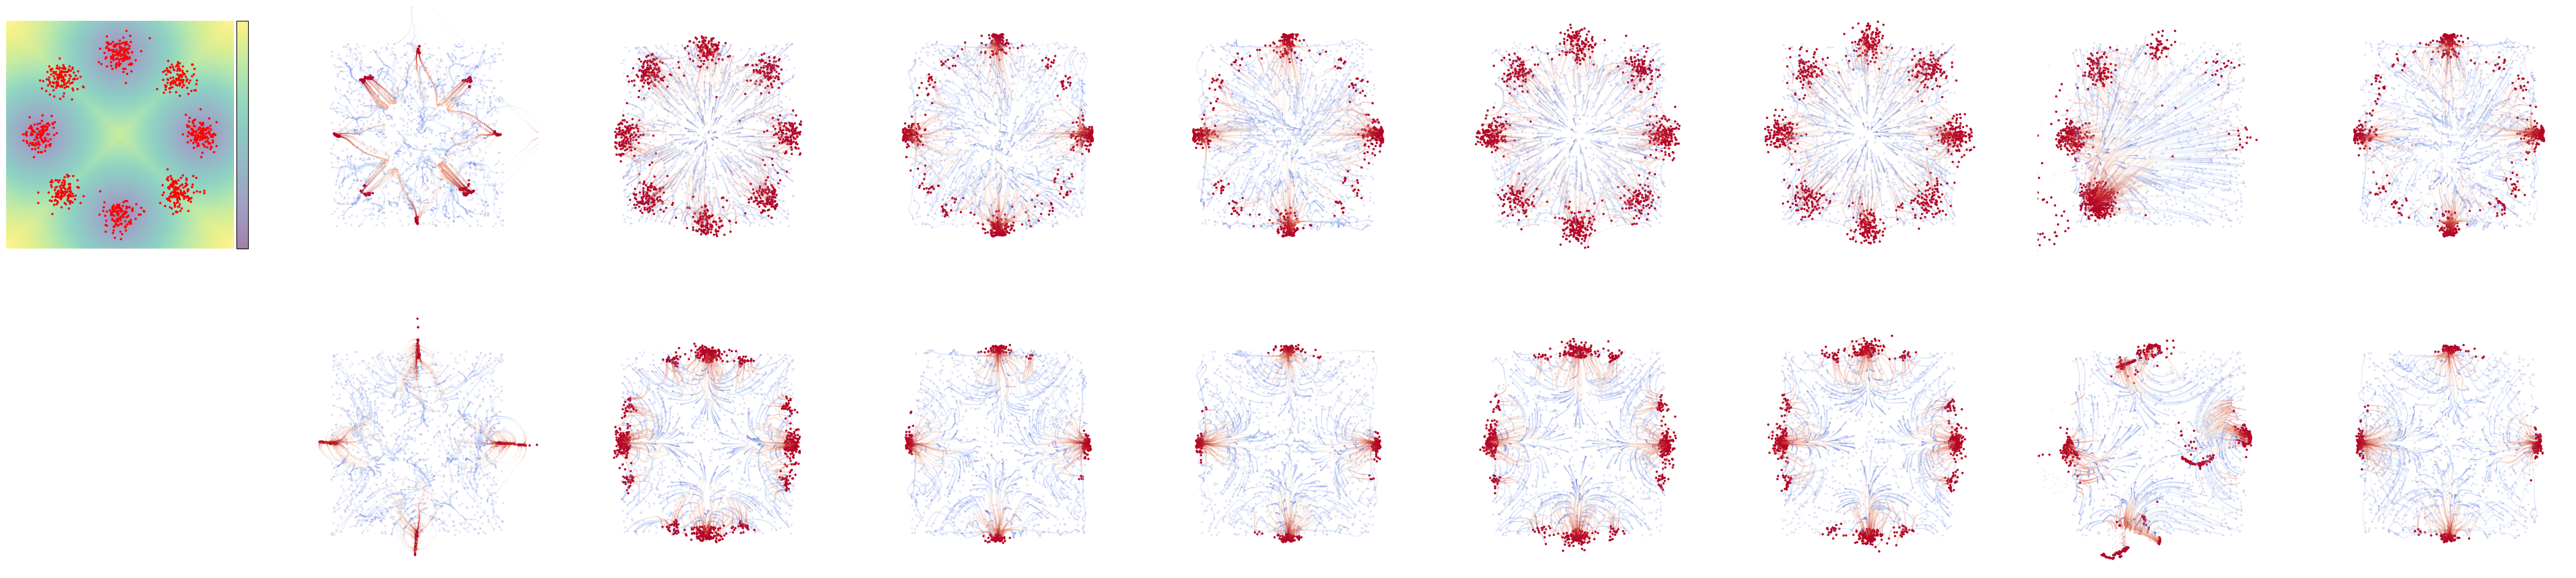

In [9]:
def plot_traj_v0(trajs, cfgs: List[GuideFnConfig], disp_b, skip_ref=False):
    blue = cm.get_cmap('coolwarm', 2)(0)
    red = cm.get_cmap('coolwarm', 2)(1)
    
    # visualize, no VF
    ndata = 2
    ncols = 9
    fig, axs = plt.subplots(ndata, ncols) 
    r = 6
    fig.set_size_inches(ncols * r, ndata * r)
    
    # data1 ref (w/o) ref (g.t.) CFM-MC CFM-GM CFM-CEG OT-CFM-MC OT-CFM-GM OT-CFM-CEG 
    # data2 ref (w/o) ref (g.t.) CFM-MC CFM-GM CFM-CEG OT-CFM-MC OT-CFM-GM OT-CFM-CEG
    # data3 ref (w/o) ref (g.t.) CFM-MC CFM-GM CFM-CEG OT-CFM-MC OT-CFM-GM OT-CFM-CEG

    size_ratio = 0.7
    nref = 1
    nmethods = ncols - nref
    
    # 1. plot ref distributions

    cfg = cfgs[0]
    # x0_dist = get_distribution(cfg.dist_pair[0])
    # x1_dist = get_distribution(cfg.dist_pair[1])
    # x0_sampler = x0_dist.sample
    # x1_sampler = x1_dist.sample
    # x1 = x1_sampler(1024).to(cfg.ode_cfg.device)
    
    # ax = axs[0, 0]
    # grid_size = 100
    # xlim, ylim = cfg.xlim * size_ratio, cfg.ylim * size_ratio
    # xs = torch.linspace(-xlim, xlim, grid_size)
    # ys = torch.linspace(-ylim, ylim, grid_size)
    # XX, YY = torch.meshgrid(xs, ys, indexing='ij')
    # grid_points = torch.stack([XX.flatten(), YY.flatten()], dim=1).to(cfg.ode_cfg.device)  # (N, 2)

    # # 2. 计算能量 J
    # with torch.no_grad():
    #     J_grid = x1_dist.get_J(grid_points).reshape(grid_size, grid_size).cpu().numpy()

    # # 3. 背景热图
    # im = ax.imshow(
    # J_grid.T,
    # extent=[-xlim, xlim, -ylim, ylim],
    # origin='lower',
    # cmap='viridis',
    # alpha=0.5,        # 半透明，方便看散点
    # aspect='auto'
    # )
    # ax.scatter(x1[:, 0].cpu(), x1[:, 1].cpu(), s=3, color='red')
    # ax.set_xlim(-cfg.xlim * size_ratio, cfg.xlim * size_ratio)
    # ax.set_ylim(-cfg.ylim * size_ratio, cfg.ylim * size_ratio)
    # ax.axis('off')
    # ax.set_aspect('auto')
    # mappable = cm.ScalarMappable(cmap='viridis')
    # mappable.set_array(J_grid)
    # vmin, vmax = (J_grid.min(), J_grid.max()) 
    # mappable.set_clim(vmin=vmin, vmax=vmax)
    # cbar = fig.colorbar(mappable, ax=ax, shrink=0.65, pad=0.1)
    # cbar.set_label('Energy $J(x,y)$')
    # ax = axs[1, 0]
    # ax.axis('off')
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    x0_dist = get_distribution(cfg.dist_pair[0])
    x1_dist = get_distribution(cfg.dist_pair[1])
    x0_sampler = x0_dist.sample
    x1_sampler = x1_dist.sample
    x1 = x1_sampler(1024).to(cfg.ode_cfg.device)

    ax = axs[0, 0]
    grid_size = 100
    xlim, ylim = cfg.xlim * size_ratio, cfg.ylim * size_ratio
    xs = torch.linspace(-xlim, xlim, grid_size)
    ys = torch.linspace(-ylim, ylim, grid_size)
    XX, YY = torch.meshgrid(xs, ys, indexing='ij')
    grid_points = torch.stack([XX.flatten(), YY.flatten()], dim=1).to(cfg.ode_cfg.device)  # (N, 2)

    # 计算能量 J
    with torch.no_grad():
        J_grid = x1_dist.get_J(grid_points).reshape(grid_size, grid_size).cpu().numpy()

    # 背景热图
    im = ax.imshow(
        J_grid.T,
        extent=[-xlim, xlim, -ylim, ylim],
        origin='lower',
        cmap='viridis',
        alpha=0.5,
        aspect='equal'   # 保持正方形
    )

    # 样本点
    ax.scatter(x1[:, 0].cpu(), x1[:, 1].cpu(), s=3, color='red')
    ax.set_xlim(-cfg.xlim * size_ratio, cfg.xlim * size_ratio)
    ax.set_ylim(-cfg.ylim * size_ratio, cfg.ylim * size_ratio)
    ax.axis('off')

    # 用 divider 给 ax 添加 colorbar，保持高度对齐
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)  # size 控制宽度, pad 控制间距
    cbar = fig.colorbar(im, cax=cax)
    # cbar.set_label('Energy $J(x,y)$')
    # vmin, vmax = (J_grid.min(), J_grid.max()) 
    cbar.set_ticks([])

    # 隐藏其他子图
    ax2 = axs[1, 0]
    ax2.axis('off')

    # 2. plot different methods
    for i in range(ndata):
        for j in range(nmethods):
            try:
                traj = trajs[i * nmethods + j]
                cfg = cfgs[i * nmethods + j]
            except:
                continue
            
            ax = axs[i, j + 1]
            # plot the start and end points with endpoint colors in the colormap

            idx = torch.randperm(cfg.ode_cfg.batch_size)[:disp_b]
            ax.scatter(traj[0, :, 0].cpu(), traj[0, :, 1].cpu(), s=3, color=blue,alpha=0.1)
            ax.scatter(traj[-1, :, 0].cpu(), traj[-1, :, 1].cpu(), s=3, color=red)
            # plot the trajectory with a gradient color
            colors = torch.linspace(0, 1, cfg.ode_cfg.num_steps).unsqueeze(1).repeat(1, disp_b).flatten().numpy()
            ax.scatter(
                traj[:, idx, 0].flatten().cpu(), 
                traj[:, idx, 1].flatten().cpu(), 
                c=plt.cm.coolwarm(colors), 
                alpha=0.5, s=0.1, marker='.'
            )
            # ax.set_title(f'{cfg.dist_pair[0]} to {cfg.dist_pair[1]}')
            ax.set_xlim(-cfg.xlim * size_ratio, cfg.xlim * size_ratio)
            ax.set_ylim(-cfg.ylim * size_ratio, cfg.ylim * size_ratio)
            ax.axis('off')

            ax.set_aspect('auto')
    return fig

def transpose(lst):
    return [list(i) for i in zip(*lst)]
def flatten(lst):
    return [item for sublist in lst for item in sublist]

trajs = [trajs_ceg_cfm, trajs_g_sim_MC_cfm, trajs_g_cov_a_cfm, trajs_g_cov_g_cfm, trajs_mc_cfm, trajs_gm_cfm,trajs_con_cfm,trajs_grad_cfm,
         trajs_ceg_lya_cfm, trajs_g_sim_MC_lya_cfm, trajs_g_cov_a_lya_cfm, trajs_g_cov_g_lya_cfm, trajs_mc_lya_cfm, trajs_gm_lya_cfm,trajs_con_lya_cfm,trajs_grad_lya_cfm]
cfgs = [guide_cfgs_ceg_cfm, guide_cfgs_g_sim_MC_cfm, guide_cfgs_g_cov_a_cfm, guide_cfgs_g_cov_g_cfm, guide_cfgs_mc_cfm, guide_cfgs_gm_cfm,guide_cfgs_con_cfm,guide_cfgs_grad_cfm,
        guide_cfgs_ceg_lya_cfm, guide_cfgs_g_sim_MC_lya_cfm, guide_cfgs_g_cov_a_lya_cfm, guide_cfgs_g_cov_g_lya_cfm, guide_cfgs_mc_lya_cfm, guide_cfgs_gm_lya_cfm,guide_cfgs_con_lya_cfm,guide_cfgs_grad_lya_cfm]# , guide_cfgs_gm_ot_cfm, guide_cfgs_ceg_ot_cfm])

fig = plot_traj_v0(flatten(transpose(trajs)), flatten(transpose(cfgs)), 256)

In [ ]:
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (needed for 3D)

def plot_J_3d(x1_dist, x1_sampler, device, 
              xlim=2.0, ylim=2.0, 
              grid_size=120,  # 网格分辨率（越大表面越细）
              n_points=2000,  # 真实样本点数
              elev=50, azim=-60,  # 视角
              discrete=False, n_bins=8,  # 若 J 为离散分段，可设 discrete=True
              cmap_surface='viridis', cmap_scatter='viridis'):
    """
    3D 可视化：z 轴为能量 J(x,y)
    - x1_dist.get_J: Tensor(B,2) -> Tensor(B,)
    - x1_sampler: 函数 n -> Tensor(n,2)
    """
    # 1) 构建网格
    xs = torch.linspace(-xlim, xlim, grid_size, device=device)
    ys = torch.linspace(-ylim, ylim, grid_size, device=device)
    XX, YY = torch.meshgrid(xs, ys, indexing='ij')
    grid = torch.stack([XX.reshape(-1), YY.reshape(-1)], dim=1)  # (G*G, 2)

    with torch.no_grad():
        J_grid = x1_dist.get_J(grid).reshape(grid_size, grid_size).cpu().numpy()

    # 2) 真实样本
    x1_true = x1_sampler(n_points).to(device)
    with torch.no_grad():
        J_true = x1_dist.get_J(x1_true).cpu().numpy()
    Xp = x1_true[:, 0].cpu().numpy()
    Yp = x1_true[:, 1].cpu().numpy()

    # 3) 画图
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection='3d')

    # 表面：stride 可以调大加速，比如 2 或 3
    surf = ax.plot_surface(XX.cpu().numpy(), YY.cpu().numpy(), J_grid, 
                           rstride=2, cstride=2, linewidth=0, antialiased=True,
                           cmap=cmap_surface, alpha=0.8)

    # 散点（与表面共用颜色范围）
    vmin, vmax = (J_grid.min(), J_grid.max()) if not discrete else (0, n_bins-1)
    sc = ax.scatter(Xp, Yp, J_true, c=J_true, s=8, cmap=cmap_scatter, 
                    vmin=vmin, vmax=vmax, depthshade=True)

    # 颜色条（共用表面的 norm，观感更一致）
    mappable = cm.ScalarMappable(cmap=cmap_surface)
    mappable.set_array(J_grid)
    mappable.set_clim(vmin=vmin, vmax=vmax)
    cbar = fig.colorbar(mappable, ax=ax, shrink=0.65, pad=0.1)
    # cbar.set_label('Energy $J(x,y)$')
    cbar.set_ticks([])
    # ax.set_xlabel('$x$')
    # ax.set_ylabel('$y$')
    # ax.set_zlabel('$J(x,y)$')
    ax.view_init(elev=elev, azim=azim)

    # 边界与网格
    ax.set_xlim(-xlim, xlim)
    ax.set_ylim(-ylim, ylim)
    ax.set_xticks([])
    ax.set_yticks([])
    # 可选：统一 z 轴范围（便于不同图比较）
    # ax.set_zlim(vmin, vmax)
    ax.set_zticks([])
    plt.tight_layout()
    plt.show()

# ==== 用法示例 ====
def transpose(lst):
    return [list(i) for i in zip(*lst)]
def flatten(lst):
    return [item for sublist in lst for item in sublist]
guide_cfgs_gm_cfm = [
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='learned', ep=1e-3, gm_type='g3', ode_cfg=ODEConfig(t_end=1.0, num_steps=100)), 
]
cfgs = flatten([guide_cfgs_gm_cfm])
cfg = cfgs[0]
x1_dist = get_distribution(cfg.dist_pair[1])
x1_sampler = x1_dist.sample
plot_J_3d(x1_dist, x1_dist.sample, cfg.ode_cfg.device, 
          xlim=cfg.xlim*0.7, ylim=cfg.ylim*0.7, grid_size=140, n_points=4000)


TypeError: 'GuideFnConfig' object is not iterable